# Fase 4 — Prueba de concepto

## Herramienta de Learning Analytics para el análisis de comentarios estudiantiles y prácticas docentes mediante PLN

**Objetivo de la PoC:** demostrar que los indicadores definidos en las fases anteriores son calculables a partir de una estructura de datos coherente y que pueden representarse en una visualización tipo tablero.

> **Importante:** los comentarios y etiquetas de este notebook son **sintéticos**. Las asignaturas se basan en la malla de Computación utilizada como contexto académico. Los resultados no representan opiniones reales de estudiantes ni resultados institucionales de la Universidad de Cuenca.


## 0. Estructura de los datos

La prueba de concepto utiliza dos tablas:

- **`comentarios_sinteticos.csv`**: contiene un comentario único y su contexto académico.
- **`menciones_practicas.csv`**: contiene una o varias prácticas docentes asociadas a cada comentario y su valoración.

La separación en dos tablas permite representar correctamente una relación **uno-a-varios**:

**un comentario → una o varias prácticas docentes**.

Esto es necesario porque un mismo comentario puede mencionar, por ejemplo, una práctica efectiva y otra malfuncional.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option("display.max_colwidth", 140)

BASE_DIR = Path(".")
if not (BASE_DIR / "comentarios_sinteticos.csv").exists():
    BASE_DIR = Path("/mnt/data")

RUTA_COMENTARIOS = BASE_DIR / "comentarios_sinteticos.csv"
RUTA_MENCIONES = BASE_DIR / "menciones_practicas.csv"

print("Comentarios:", RUTA_COMENTARIOS)
print("Menciones:", RUTA_MENCIONES)


Comentarios: comentarios_sinteticos.csv
Menciones: menciones_practicas.csv


## 1. Carga y descripción del dataset

### ¿Qué representa cada tabla?

**Tabla de comentarios**
- `id_comentario`: identificador técnico del comentario.
- `comentario`: texto sintético de retroalimentación estudiantil.
- `asignatura`: asignatura de la carrera de Computación usada como contexto.
- `periodo_academico`: período sintético asociado al comentario.

**Tabla de menciones**
- `id_comentario`: enlaza cada mención con su comentario.
- `practica_docente`: práctica docente identificada.
- `valoracion`: clasificación de la práctica como `efectiva`, `malfuncional` o `ambigua`.

### Nota sobre estudiantes

El dataset **no contiene identificadores de estudiantes**, ni reales ni sintéticos. Por tanto, no es posible calcular cuántos estudiantes únicos están representados. La unidad de análisis de esta PoC es el **comentario**, no el estudiante. Esta decisión es coherente con el diseño de privacidad de la herramienta.


In [2]:
comentarios = pd.read_csv(RUTA_COMENTARIOS)
menciones = pd.read_csv(RUTA_MENCIONES)

print("Dimensión comentarios:", comentarios.shape)
print("Dimensión menciones:", menciones.shape)

display(comentarios.head())
display(menciones.head())


Dimensión comentarios: (200, 4)
Dimensión menciones: (301, 3)


,id_comentario,comentario,asignatura,periodo_academico
0,C001,La explicación sobre arquitecturas de redes fue precisa y fácil de relacionar con lo visto antes. Este aspecto fue especialmente visible...,Redes Neuronales,2025-2
1,C002,La presentación de algoritmos resultó poco clara y mezcló varios conceptos a la vez.,"Programación I: Algoritmos, Datos y Estructuras",2025-2
2,C003,La clase de minería de datos cambió varias veces de actividad y fue difícil seguir una secuencia.,Almacén y Minería de Datos,2026-1
3,C004,Trabajar ejemplos paso a paso permitió entender mejor procesos ETL.,Almacén y Minería de Datos,2025-2
4,C005,"Se mostraron buenos ejemplos de normalización, pero habría sido útil incluir más variedad. La revisión de los ejercicios de normalizació...",Base de Datos I: Diseño y Principios,2025-2


,id_comentario,practica_docente,valoracion
0,C001,Claridad explicativa,efectiva
1,C002,Claridad explicativa,malfuncional
2,C003,Organización de la clase,malfuncional
3,C004,Uso de ejemplos,efectiva
4,C005,Uso de ejemplos,ambigua


In [3]:
resumen_dataset = pd.DataFrame({
    "Medida": [
        "Comentarios únicos",
        "Estudiantes únicos",
        "Asignaturas",
        "Períodos académicos",
        "Prácticas docentes",
        "Valoraciones",
        "Menciones totales"
    ],
    "Valor": [
        comentarios["id_comentario"].nunique(),
        "No disponible: no se modelan estudiantes",
        comentarios["asignatura"].nunique(),
        comentarios["periodo_academico"].nunique(),
        menciones["practica_docente"].nunique(),
        menciones["valoracion"].nunique(),
        len(menciones)
    ]
})

display(resumen_dataset)

print("\nPeríodos cubiertos:", sorted(comentarios["periodo_academico"].unique()))
print("\nAsignaturas representadas:")
for asignatura in sorted(comentarios["asignatura"].unique()):
    print("-", asignatura)


,Medida,Valor
0,Comentarios únicos,200
1,Estudiantes únicos,No disponible: no se modelan estudiantes
2,Asignaturas,10
3,Períodos académicos,2
4,Prácticas docentes,5
5,Valoraciones,3
6,Menciones totales,301



Períodos cubiertos: ['2025-2', '2026-1']

Asignaturas representadas:
- Almacén y Minería de Datos
- Aprendizaje de Máquina
- Base de Datos I: Diseño y Principios
- Ciencia de los Datos
- Gráficos por Computador
- Inteligencia Artificial
- Probabilidad y Estadística
- Programación I: Algoritmos, Datos y Estructuras
- Programación II: Estructura de Datos y Análisis de Algoritmos
- Redes Neuronales


## 2. Limpieza y validación de consistencia

Aunque los datos fueron generados mediante un script controlado, la PoC valida explícitamente:

1. valores faltantes;
2. IDs duplicados en la tabla de comentarios;
3. menciones huérfanas;
4. prácticas y valoraciones fuera de catálogo;
5. repetición de la misma práctica dentro de un comentario;
6. existencia de comentarios con múltiples prácticas.

Estas comprobaciones son importantes porque los indicadores se calculan sobre **comentarios únicos**, no simplemente sobre el número de filas.


In [4]:
PRACTICAS_VALIDAS = {
    "Claridad explicativa",
    "Retroalimentación",
    "Organización de la clase",
    "Uso de ejemplos",
    "Instrucciones de evaluación",
}
VALORACIONES_VALIDAS = {"efectiva", "malfuncional", "ambigua"}

validaciones = {
    "Nulos en comentarios": int(comentarios.isna().sum().sum()),
    "Nulos en menciones": int(menciones.isna().sum().sum()),
    "IDs duplicados en comentarios": int(comentarios["id_comentario"].duplicated().sum()),
    "Menciones huérfanas": int((~menciones["id_comentario"].isin(comentarios["id_comentario"])).sum()),
    "Prácticas fuera de catálogo": int((~menciones["practica_docente"].isin(PRACTICAS_VALIDAS)).sum()),
    "Valoraciones fuera de catálogo": int((~menciones["valoracion"].isin(VALORACIONES_VALIDAS)).sum()),
    "Práctica repetida dentro del mismo comentario": int(
        menciones.duplicated(subset=["id_comentario", "practica_docente"]).sum()
    ),
}

display(pd.DataFrame(validaciones.items(), columns=["Validación", "Incidencias"]))

menciones_por_comentario = menciones.groupby("id_comentario").size()
print("Comentarios con más de una práctica:", int((menciones_por_comentario > 1).sum()))
print("Máximo de prácticas en un comentario:", int(menciones_por_comentario.max()))


,Validación,Incidencias
0,Nulos en comentarios,0
1,Nulos en menciones,0
2,IDs duplicados en comentarios,0
3,Menciones huérfanas,0
4,Prácticas fuera de catálogo,0
5,Valoraciones fuera de catálogo,0
6,Práctica repetida dentro del mismo comentario,0


Comentarios con más de una práctica: 88
Máximo de prácticas en un comentario: 3


## 3. Construcción de los indicadores

Se implementan los indicadores definidos en la Fase 3:

### I01 — Número de comentarios únicos analizados
Número de `id_comentario` distintos dentro de los filtros activos.

### I02 — Comentarios únicos que mencionan una práctica
Para cada práctica \(j\), se cuentan los comentarios únicos que la mencionan.

### I03 — Porcentaje de comentarios que mencionan cada práctica

$$
P_j = \frac{N_j}{N} \times 100
$$

donde:

- $N$ = total de comentarios únicos.
- $N_j$ = comentarios únicos que mencionan la práctica $j$.

Los porcentajes de distintas prácticas **pueden sumar más de 100 %**, porque un comentario puede mencionar varias prácticas.

### I04 — Distribución de valoraciones dentro de una práctica

$$
P(v \mid j) = \frac{N_{jv}}{N_j} \times 100
$$

donde:

- $N_{jv}$ = número de comentarios que mencionan la práctica $j$ con una valoración determinada.
- $N_j$ = número total de comentarios que mencionan la práctica $j$.


In [5]:
def calcular_indicadores(comentarios_df, menciones_df, asignatura=None, periodo=None):
    comentarios_f = comentarios_df.copy()

    if asignatura is not None:
        comentarios_f = comentarios_f[comentarios_f["asignatura"] == asignatura]
    if periodo is not None:
        comentarios_f = comentarios_f[comentarios_f["periodo_academico"] == periodo]

    ids_validos = set(comentarios_f["id_comentario"])
    menciones_f = menciones_df[menciones_df["id_comentario"].isin(ids_validos)].copy()

    # I01
    N = comentarios_f["id_comentario"].nunique()

    # I02 e I03
    por_practica = (
        menciones_f.groupby("practica_docente")["id_comentario"]
        .nunique()
        .rename("N_j")
        .reset_index()
    )
    por_practica["P_j"] = np.where(N > 0, por_practica["N_j"] / N * 100, 0)

    # I04
    distribucion_valoracion = (
        menciones_f.groupby(["practica_docente", "valoracion"])["id_comentario"]
        .nunique()
        .rename("N_jv")
        .reset_index()
    )
    distribucion_valoracion = distribucion_valoracion.merge(
        por_practica[["practica_docente", "N_j"]],
        on="practica_docente",
        how="left"
    )
    distribucion_valoracion["P_v_j"] = np.where(
        distribucion_valoracion["N_j"] > 0,
        distribucion_valoracion["N_jv"] / distribucion_valoracion["N_j"] * 100,
        0
    )

    return N, por_practica.sort_values("P_j", ascending=False), distribucion_valoracion


N, indicadores_practica, indicadores_valoracion = calcular_indicadores(comentarios, menciones)

print("I01 — Comentarios únicos analizados:", N)
display(indicadores_practica)
display(indicadores_valoracion.head(15))


I01 — Comentarios únicos analizados: 200


,practica_docente,N_j,P_j
0,Claridad explicativa,77,38.5
4,Uso de ejemplos,63,31.5
3,Retroalimentación,56,28.0
2,Organización de la clase,54,27.0
1,Instrucciones de evaluación,51,25.5


,practica_docente,valoracion,N_jv,N_j,P_v_j
0,Claridad explicativa,ambigua,10,77,12.987013
1,Claridad explicativa,efectiva,46,77,59.740260
2,Claridad explicativa,malfuncional,21,77,27.272727
3,Instrucciones de evaluación,ambigua,4,51,7.843137
4,Instrucciones de evaluación,efectiva,29,51,56.862745
5,Instrucciones de evaluación,malfuncional,18,51,35.294118
6,Organización de la clase,ambigua,4,54,7.407407
7,Organización de la clase,efectiva,31,54,57.407407
8,Organización de la clase,malfuncional,19,54,35.185185
9,Retroalimentación,ambigua,11,56,19.642857


### Comprobaciones matemáticas

Se validan dos propiedades clave:

- cada comentario se cuenta una sola vez dentro de una práctica;
- la distribución de valoraciones de cada práctica debe sumar aproximadamente 100 %.


In [6]:
# Suma de porcentajes entre prácticas: puede superar 100 %
suma_practicas = indicadores_practica["P_j"].sum()
print(f"Suma de P_j entre prácticas: {suma_practicas:.2f}%")
print("¿Puede superar 100 %?:", suma_practicas > 100)

# I04 debe sumar ~100 % dentro de cada práctica
control_i04 = (
    indicadores_valoracion.groupby("practica_docente")["P_v_j"]
    .sum()
    .round(6)
    .reset_index(name="suma_porcentajes")
)
display(control_i04)


Suma de P_j entre prácticas: 150.50%
¿Puede superar 100 %?: True


,practica_docente,suma_porcentajes
0,Claridad explicativa,100.0
1,Instrucciones de evaluación,100.0
2,Organización de la clase,100.0
3,Retroalimentación,100.0
4,Uso de ejemplos,100.0


## 4. Visualización tipo tablero — Wireframe 1: Panorama general

La siguiente visualización reproduce conceptualmente el **panorama general de prácticas docentes**:

- total de comentarios analizados;
- número de prácticas identificadas;
- porcentaje de comentarios que menciona cada práctica.

La visualización utiliza **Plotly** y se recalcula a partir de los datos procesados.


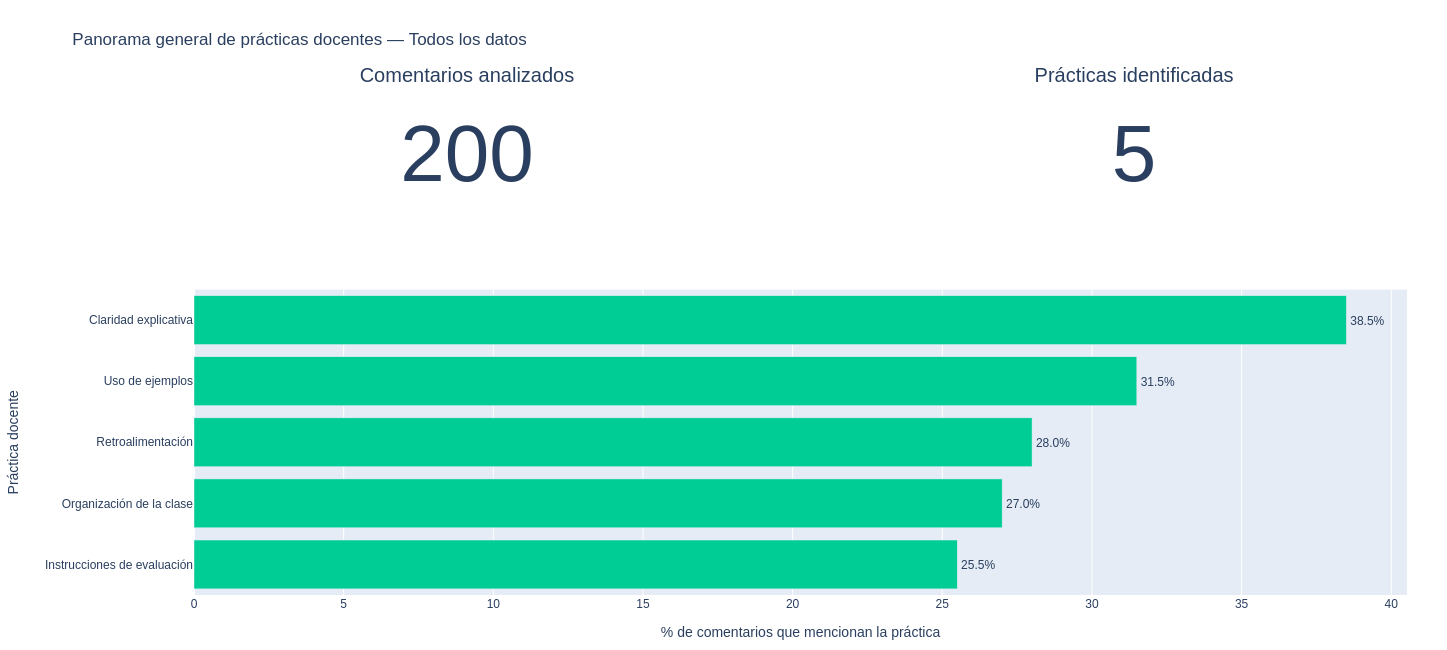

In [7]:
def construir_tablero_panorama(comentarios_df, menciones_df, asignatura=None, periodo=None):
    N, por_practica, _ = calcular_indicadores(
        comentarios_df, menciones_df, asignatura=asignatura, periodo=periodo
    )

    titulo_contexto = []
    if asignatura:
        titulo_contexto.append(asignatura)
    if periodo:
        titulo_contexto.append(periodo)
    contexto = " · ".join(titulo_contexto) if titulo_contexto else "Todos los datos"

    fig = make_subplots(
        rows=2, cols=2,
        specs=[
            [{"type": "indicator"}, {"type": "indicator"}],
            [{"type": "bar", "colspan": 2}, None],
        ],
        row_heights=[0.28, 0.72],
        vertical_spacing=0.16
    )

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=N,
            title={"text": "Comentarios analizados"}
        ),
        row=1, col=1
    )

    fig.add_trace(
        go.Indicator(
            mode="number",
            value=por_practica["practica_docente"].nunique(),
            title={"text": "Prácticas identificadas"}
        ),
        row=1, col=2
    )

    fig.add_trace(
        go.Bar(
            y=por_practica["practica_docente"],
            x=por_practica["P_j"],
            orientation="h",
            text=por_practica["P_j"].map(lambda x: f"{x:.1f}%"),
            textposition="outside",
            customdata=por_practica[["N_j"]],
            hovertemplate=(
                "<b>%{y}</b><br>"
                "Comentarios: %{customdata[0]}<br>"
                "Porcentaje: %{x:.2f}%<extra></extra>"
            ),
            name="% de comentarios"
        ),
        row=2, col=1
    )

    fig.update_yaxes(
        categoryorder="total ascending",
        title_text="Práctica docente",
        row=2, col=1
    )
    fig.update_xaxes(
        title_text="% de comentarios que mencionan la práctica",
        rangemode="tozero",
        row=2, col=1
    )

    fig.update_layout(
        title=f"Panorama general de prácticas docentes — {contexto}",
        height=650,
        showlegend=False,
        margin=dict(l=40, r=40, t=90, b=40)
    )

    return fig


fig_panorama = construir_tablero_panorama(comentarios, menciones)
fig_panorama.show()


### Ejemplo de filtro

Los indicadores deben recalcularse cuando cambia la asignatura o el período.  
La siguiente celda demuestra el mismo cálculo para una combinación concreta.


Contexto: Ciencia de los Datos · 2026-1
Comentarios únicos: 10


,practica_docente,N_j,P_j
0,Claridad explicativa,4,40.0
1,Instrucciones de evaluación,3,30.0
2,Organización de la clase,3,30.0
3,Retroalimentación,3,30.0
4,Uso de ejemplos,1,10.0


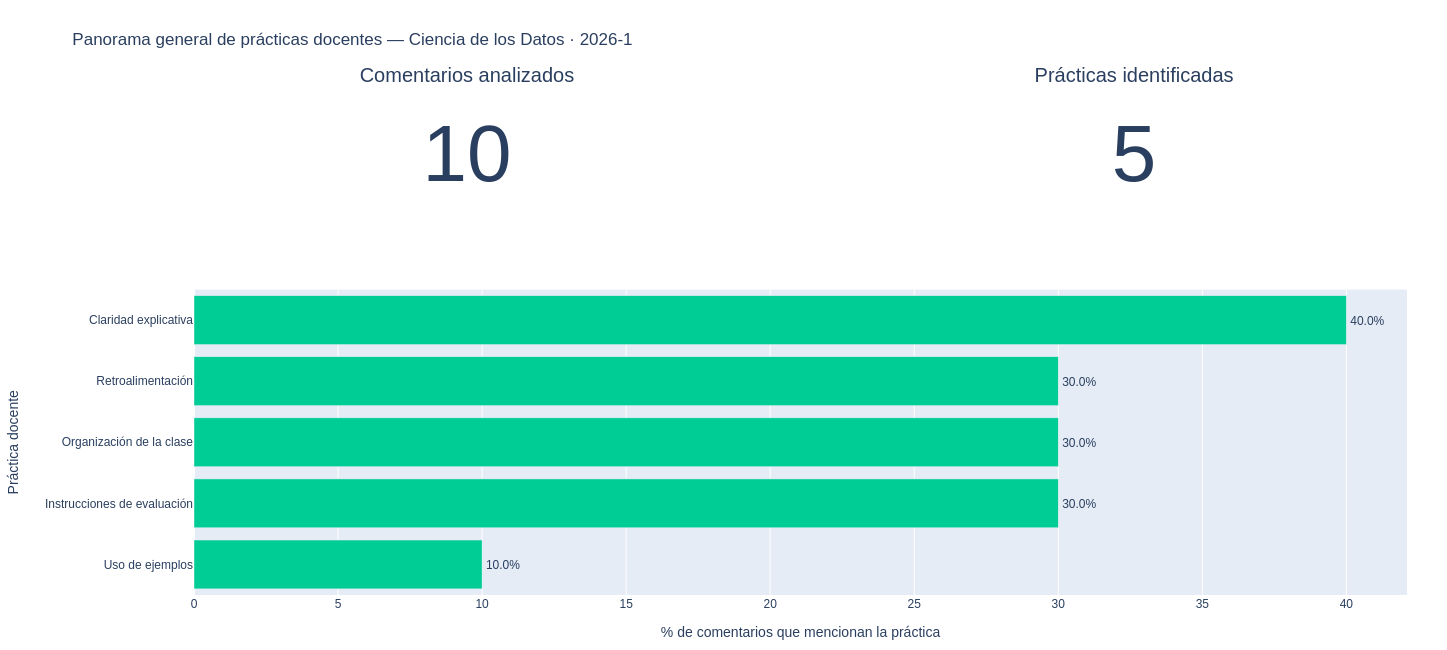

In [8]:
ASIGNATURA_EJEMPLO = "Ciencia de los Datos"
PERIODO_EJEMPLO = "2026-1"

N_filtrado, indicadores_filtrados, _ = calcular_indicadores(
    comentarios,
    menciones,
    asignatura=ASIGNATURA_EJEMPLO,
    periodo=PERIODO_EJEMPLO
)

print(f"Contexto: {ASIGNATURA_EJEMPLO} · {PERIODO_EJEMPLO}")
print("Comentarios únicos:", N_filtrado)
display(indicadores_filtrados)

construir_tablero_panorama(
    comentarios,
    menciones,
    asignatura=ASIGNATURA_EJEMPLO,
    periodo=PERIODO_EJEMPLO
).show()


## 5. Visualización complementaria — Wireframe 2: valoración de una práctica

Aunque el requisito mínimo solicita una visualización tipo tablero, se incluye también una vista de detalle para mostrar el indicador **I04**.

Esta vista responde:

> **¿Cómo están valorando los comentarios una práctica docente concreta?**


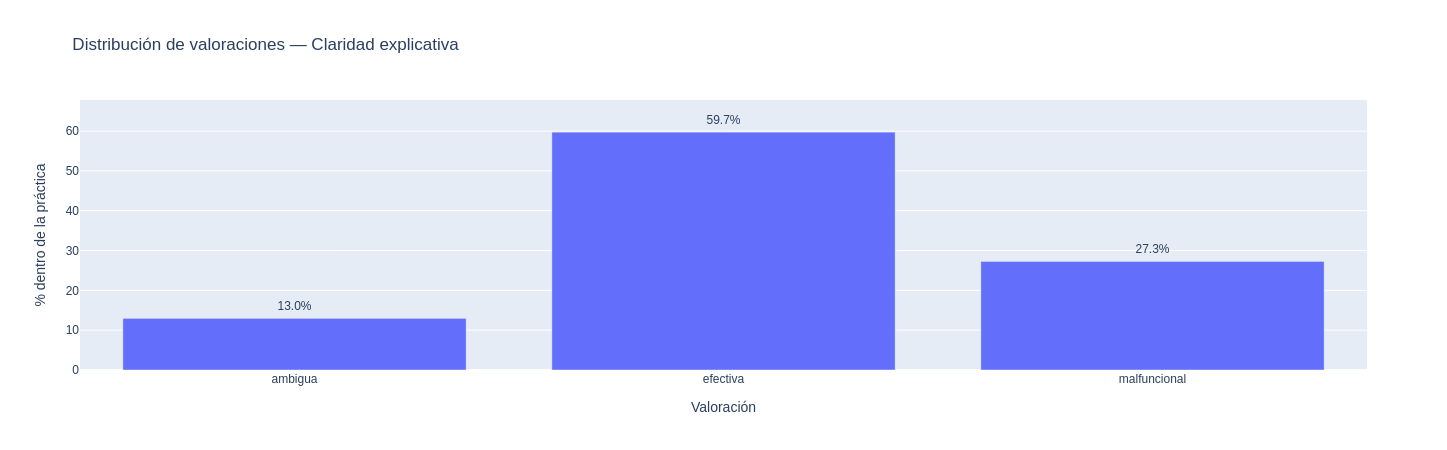

In [9]:
PRACTICA_EJEMPLO = "Claridad explicativa"

_, _, detalle_valoracion = calcular_indicadores(comentarios, menciones)
detalle = (
    detalle_valoracion[detalle_valoracion["practica_docente"] == PRACTICA_EJEMPLO]
    .sort_values("valoracion")
)

fig_detalle = go.Figure(
    go.Bar(
        x=detalle["valoracion"],
        y=detalle["P_v_j"],
        text=detalle["P_v_j"].map(lambda x: f"{x:.1f}%"),
        textposition="outside",
        customdata=detalle[["N_jv"]],
        hovertemplate=(
            "<b>%{x}</b><br>"
            "Comentarios: %{customdata[0]}<br>"
            "Porcentaje: %{y:.2f}%<extra></extra>"
        )
    )
)

fig_detalle.update_layout(
    title=f"Distribución de valoraciones — {PRACTICA_EJEMPLO}",
    xaxis_title="Valoración",
    yaxis_title="% dentro de la práctica",
    height=450,
    showlegend=False
)

fig_detalle.show()


## 6. ¿Se requiere un modelo predictivo?

**No aplica en esta prueba de concepto.**

La herramienta propuesta tiene un propósito **descriptivo y diagnóstico**:

- describe qué prácticas aparecen;
- calcula con qué frecuencia se mencionan;
- muestra cómo se distribuyen sus valoraciones;
- permite contrastar los indicadores con evidencia textual.

No intenta predecir abandono, rendimiento, aprobación u otro resultado futuro. Por ello, no corresponde incorporar regresión logística ni árbol de decisión únicamente para cumplir formalmente un requisito destinado a herramientas predictivas.


## 7. Lo que este prototipo no puede decir todavía

Esta prueba de concepto demuestra que los indicadores son **calculables y visualizables**, pero todavía no permite afirmar que:

1. **los resultados representen a estudiantes reales de la Universidad de Cuenca**, porque los comentarios son sintéticos;
2. **el modelo de PLN identifique correctamente las prácticas y valoraciones**, porque en esta PoC las etiquetas ya vienen generadas junto con los comentarios;
3. **las frecuencias observadas reflejen problemas o fortalezas docentes reales**, porque las distribuciones fueron creadas artificialmente;
4. **una frecuencia alta implique causalidad o necesidad automática de intervención**;
5. **la herramienta mejore efectivamente las decisiones docentes**, porque todavía no se ha comparado su uso frente a la revisión manual;
6. **la interfaz sea suficientemente usable para docentes reales**, porque aún requiere evaluación con usuarios;
7. **el tratamiento institucional de los comentarios esté resuelto**, porque la fuente real, periodicidad, autorización y mecanismo de acceso todavía deben confirmarse.

Estos límites orientan la siguiente fase del trabajo: la propuesta deberá ser validada con datos reales autorizados y con evidencia técnica, pedagógica y de usabilidad antes de interpretar sus resultados como apoyo efectivo para la toma de decisiones.


## 8. Conclusión de la prueba de concepto

La PoC demuestra que la estructura de datos definida en las fases anteriores permite calcular de forma reproducible:

- **I01:** comentarios únicos analizados;
- **I02:** comentarios únicos que mencionan cada práctica;
- **I03:** porcentaje de comentarios que menciona cada práctica;
- **I04:** distribución de valoraciones dentro de cada práctica.

También demuestra que estos indicadores pueden representarse en una visualización tipo tablero coherente con los wireframes definidos para la herramienta.

**Alcance demostrado:** calculabilidad y visualización de los indicadores.  
**Alcance no demostrado:** precisión real del PLN, representatividad institucional e impacto pedagógico.
